# CORP Reliability Diagram

**Family:** Machine learning &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Machine learning:* Evaluate and explain fitted models: classification performance, calibration, learning curves, residuals, feature importance and feature effects.

## Design purpose

A reliability diagram built the CORP way (consistent, optimally binned, reproducible). Instead of averaging outcomes in arbitrary bins, it fits an isotonic (pool-adjacent-violators) regression of outcomes on predicted probabilities. The bins come out of the data automatically. A consistency band shows how far a perfectly calibrated model could wander from the diagonal by chance, and the Brier score splits into miscalibration, discrimination and uncertainty.

## When to use

- Check whether a probability model (default, churn, fraud, recession odds) is calibrated, i.e. whether 10% predictions come true 10% of the time
- Compare calibration across models or vintages without the result depending on how you chose bins
- Report calibration and discrimination as numbers that add up to the Brier score

## Avoid when

- Only the ranking of cases matters (use ROC or precision-recall)
- The outcome is continuous rather than binary (use a Murphy diagram or a residual plot)
- There are only a few dozen cases; the band will be too wide to say anything

## Alternatives

- Classic binned calibration plot (simpler, but the shape changes with the bins)
- Murphy diagram (compares forecasts over all decision thresholds)
- Decision curve (value of acting on the predictions)

## Design tips

- What it fixes: a classic 10-bin calibration curve can change shape when you move the bin edges; the PAV fit is unique, so two analysts get the same picture from the same data
- Points outside the gray band are miscalibration that chance alone is unlikely to explain
- Read the decomposition: MCB is the cost of miscalibration (fixable by recalibration), DSC is the skill of ranking, UNC is the difficulty of the problem
- Show the histogram of predictions; calibration where few predictions fall is unreliable

## Example

A simulated credit book of 3,000 loans. The true default risk depends on a latent score, and the model's predicted default probabilities are over-confident: too low for safe borrowers, too high for risky ones.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve

### Data

In [2]:
rng = np.random.default_rng(21)
n = 3000
# Simulated credit book: true default risk comes from a latent score; the model over-reacts to it.
score = rng.normal(0, 1, n)
true_pd = 1 / (1 + np.exp(-(-2.2 + 1.1 * score)))
default = rng.binomial(1, true_pd)
pred_pd = 1 / (1 + np.exp(-(-2.5 + 1.8 * score + rng.normal(0, 0.25, n))))
df = pd.DataFrame({"pred_pd": pred_pd, "default": default})
df.describe().round(3)

,pred_pd,default
count,3000.000,3000.000
mean,0.163,0.137
std,0.197,0.344
min,0.000,0.000
25%,0.025,0.000
50%,0.080,0.000
75%,0.224,0.000
max,0.979,1.000


### Plot

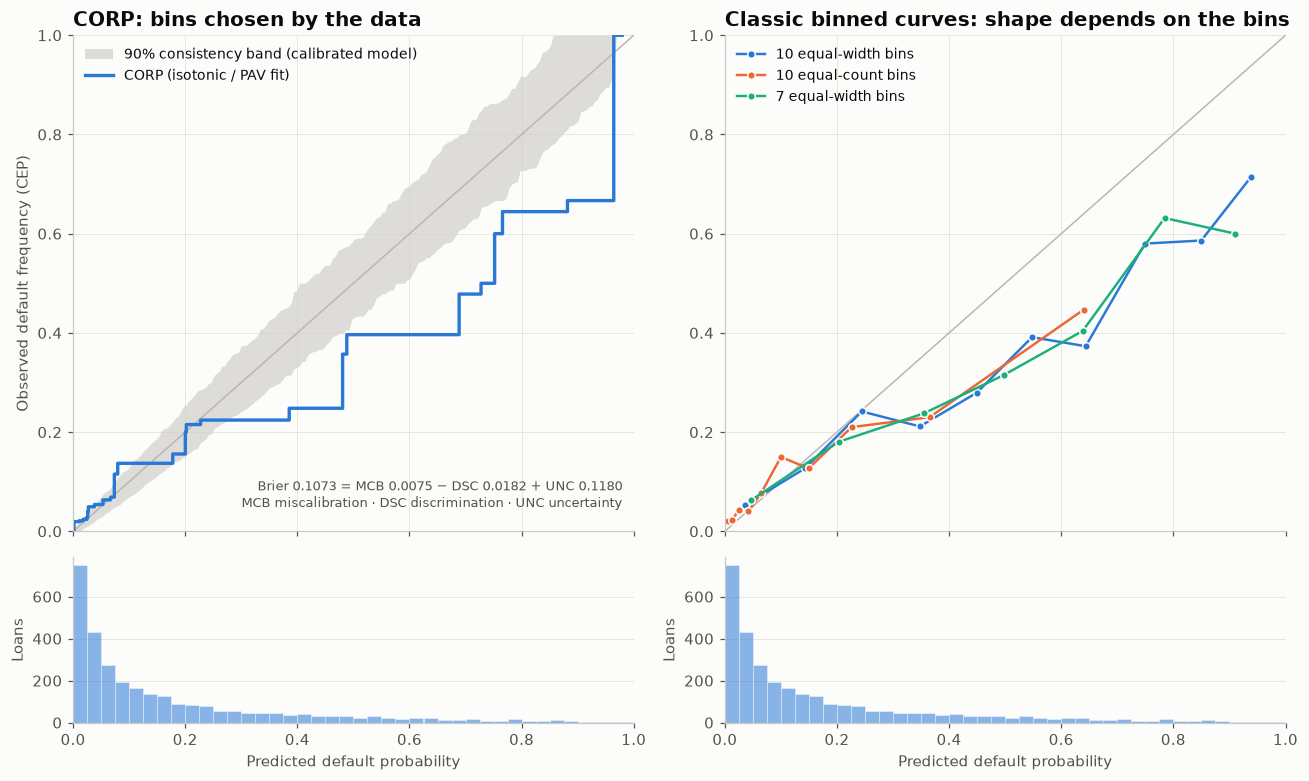

In [3]:
order = np.argsort(df["pred_pd"].to_numpy())
p = df["pred_pd"].to_numpy()[order]
y = df["default"].to_numpy()[order]

def pav(x, outcome):
    return IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(x, outcome)

cep = pav(p, y).predict(p)  # CORP: conditional event probability from pool-adjacent-violators

# 90% consistency band: refit PAV on outcomes drawn from a perfectly calibrated model (y* ~ Bernoulli(p)).
rng_band = np.random.default_rng(7)
grid = np.linspace(p.min(), p.max(), 200)
sims = np.array([pav(p, rng_band.binomial(1, p)).predict(grid) for _ in range(300)])
band_lo, band_hi = np.quantile(sims, [0.05, 0.95], axis=0)

# CORP decomposition of the Brier score: S = MCB - DSC + UNC
S = np.mean((p - y) ** 2)
S_cal = np.mean((cep - y) ** 2)
S_ref = np.mean((y.mean() - y) ** 2)
MCB, DSC, UNC = S - S_cal, S_ref - S_cal, S_ref

fig, axes = plt.subplots(2, 2, figsize=(12, 7.2), height_ratios=[3, 1], sharex="col")
ax, ax2 = axes[0]
for a in (ax, ax2):
    a.plot([0, 1], [0, 1], color=GRAY, linewidth=1)
    a.set_xlim(0, 1)
    a.set_ylim(0, 1)

ax.fill_between(grid, band_lo, band_hi, color="#d0cfca", alpha=0.7, linewidth=0,
                label="90% consistency band (calibrated model)")
ax.step(p, cep, where="post", color=PALETTE[0], linewidth=2.2, label="CORP (isotonic / PAV fit)")
ax.set_ylabel("Observed default frequency (CEP)")
ax.set_title("CORP: bins chosen by the data")
ax.text(0.98, 0.04,
        f"Brier {S:.4f} = MCB {MCB:.4f} − DSC {DSC:.4f} + UNC {UNC:.4f}\n"
        "MCB miscalibration · DSC discrimination · UNC uncertainty",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=8.5, color="#52514e")
ax.legend(loc="upper left", fontsize=9)

for color, (label, n_bins, strategy) in zip(
        PALETTE, [("10 equal-width bins", 10, "uniform"), ("10 equal-count bins", 10, "quantile"),
                  ("7 equal-width bins", 7, "uniform")]):
    frac, mean_pred = calibration_curve(y, p, n_bins=n_bins, strategy=strategy)
    ax2.plot(mean_pred, frac, "o-", color=color, markersize=5, linewidth=1.6, label=label,
             markeredgecolor="#fcfcfb", markeredgewidth=1)
ax2.set_title("Classic binned curves: shape depends on the bins")
ax2.legend(loc="upper left", fontsize=9)

for a in axes[1]:
    a.hist(p, bins=np.linspace(0, 1, 41), color=PALETTE[0], alpha=0.55, edgecolor="#fcfcfb", linewidth=0.5)
    a.set_xlabel("Predicted default probability")
    a.set_ylabel("Loans")
    a.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

## How to read it

Left: above a predicted probability of about 0.25 the blue CORP curve runs well below the diagonal and outside the gray consistency band. When the model says 50%, only about 25–40% of those loans default: it is over-confident for risky borrowers. The decomposition shows that miscalibration (MCB) costs a noticeable part of the Brier score, and recalibration could remove it. Right: the classic binned curves on the same predictions zig-zag and shift with the bin choice, especially above 0.6 where few loans sit.

## Reference

This method comes from the research literature:

- Dimitriadis, T., Gneiting, T. & Jordan, A. I. (2021). Stable reliability diagrams for probabilistic classifiers. PNAS 118(8), e2016191118. <https://doi.org/10.1073/pnas.2016191118>

---
Standalone script: [`corp_reliability_diagram.py`](corp_reliability_diagram.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)